In [78]:
from dataclasses import dataclass, field
from typing import Optional, Sequence
from pathlib import Path
from matplotlib import font_manager
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import XGate
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

from src.linear_tag import (
    int_to_bits,
    bits_to_int,
    gf2_rank,
    tag_value,
    Transcript,
    KeyedLinearTagModel
)

In [79]:
# Resolve the project root.
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RES_DIR = PROJECT_ROOT / "res"
RES_DIR.mkdir(parents=True, exist_ok=True)

# Require Times New Roman rather than silently substituting a font.
available_fonts = {f.name for f in font_manager.fontManager.ttflist}

if "Times New Roman" not in available_fonts:
    raise RuntimeError(
        "Times New Roman is not available to Matplotlib."
    )

plt.rcParams.update({
    "font.family": "Times New Roman",
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "mathtext.fallback": "stix",
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
    "savefig.dpi": 600,
})


def save_pdf(fig, filename):
    """Save a publication-quality vector PDF to res/."""
    path = RES_DIR / f"{filename}.pdf"

    fig.savefig(
        path,
        format="pdf",
        bbox_inches="tight",
        dpi=600,
    )

    print(f"Saved: {path}")


# Keyed Linear-Tag Construction: Experimental setup

This notebook studies the keyed linear-tag construction of
Section IV of the reference paper.

A model consists of `nu` independently keyed circuit blocks.
Each block operates on the same computational-basis input
and produces one measurement transcript.

The paper-exact construction uses:

$$
m=n,\qquad 1\le s\le n,
$$

with XOR permutations

$$
\pi_t(x)=x\oplus t
$$

and secret matrices

$$
B_j\in\mathbb F_2^{s\times n},
\qquad j=1,\ldots,\nu.
$$

All model parameters, key matrices, and permutation choices
are fixed at initialization.

We first inspect the model and its logical resources, then
study its quantum circuits and classical transcript sampler.


![Block diagram](./img/blocchi.png)


In [80]:
from IPython.display import display
# ============================================================
# EXPERIMENT PARAMETERS
# ============================================================

N = 3
M = N
S = 2
NU = 2

SEED = 42
X = 0b101 #explicit bit format

# None: generate independent pseudorandom binary matrices.
KEY_MATRICES = None

# To use explicit keys instead, uncomment:
#
# KEY_MATRICES = [
#     np.array([
#         [1, 0, 1],
#         [0, 1, 0],
#     ], dtype=np.uint8),
#
#     np.array([
#         [0, 0, 1],
#         [1, 1, 0],
#     ], dtype=np.uint8),
# ]

# None: use the exact XOR permutation family of the paper.
MASKS = None

# ============================================================
# INITIALIZATION
# ============================================================

model = KeyedLinearTagModel(
    n=N,
    m=M,
    s=S,
    nu=NU,
    masks=MASKS,
    key_matrices=KEY_MATRICES,
    seed=SEED,
)

# Full information is printed immediately after initialization.
model.describe(show_keys=True)

print(f"\nInput x = {X:0{N}b}")

# Inspect the logical resource counts from Table I.
display(model.resource_table())

KEYED LINEAR-TAG MODEL
Paper-exact construction : True
System qubits (n)        : 3
Index qubits (m)         : 3
Tag qubits (s)           : 2
Keyed blocks (nu)        : 2
Permutation labels (K)  : 8
Qubits per block         : 8
Seed                     : 42
Key source               : Pseudorandom
Permutation family       : pi_t(x) = x XOR t

Secret key B_1:
[[1 0 1]
 [0 1 1]]
rank(B_1) = 2

Secret key B_2:
[[1 1 1]
 [1 0 0]]
rank(B_2) = 2

DECODING INFORMATION
rank(A)                  : 3
Full column rank         : True
Random-key failure bound : 0.4375
Random-key inversion bound: 0.7916666666666666

TOTAL LOGICAL RESOURCES
executions               : 2
qubits                   : 8
hadamards                : 12
cnot                     : 14
expected_cnot            : 12.0
logical_two_qubit_depth  : 7
measured_bits            : 16
secret_key_bits          : 12
classical_decoding       : O(nu * s * n^2)

Input x = 101


,Block 1,Block 2,Total
Resource,,,
Executions,1.0,1.0,2
Qubits,8.0,8.0,8
Hadamard gates,6.0,6.0,12
CNOT gates,7.0,7.0,14
Expected CNOT gates,6.0,6.0,12.0
Logical two-qubit depth,3.0,4.0,7
Measured bits,8.0,8.0,16
Secret-key bits,6.0,6.0,12
Classical decoding,NaN,NaN,O(nu * s * n^2)


In [81]:
print("Total CNOTs:", model.resources["total"]["cnot"])
print("Total executions:", model.resources["total"]["executions"])
print("Rank(A):", model.resources["rank_A"])
print("Full column rank:", model.resources["full_column_rank"])

Total CNOTs: 14
Total executions: 2
Rank(A): 3
Full column rank: True


XOR permutation family:


,Label t,Mask,Output
0,000,000,101
1,001,001,100
2,010,010,111
3,011,011,110
4,100,100,001
5,101,101,000
6,110,110,011
7,111,111,010



Block 1/2
Key matrix B_1:
[[1 0 1]
 [0 1 1]]


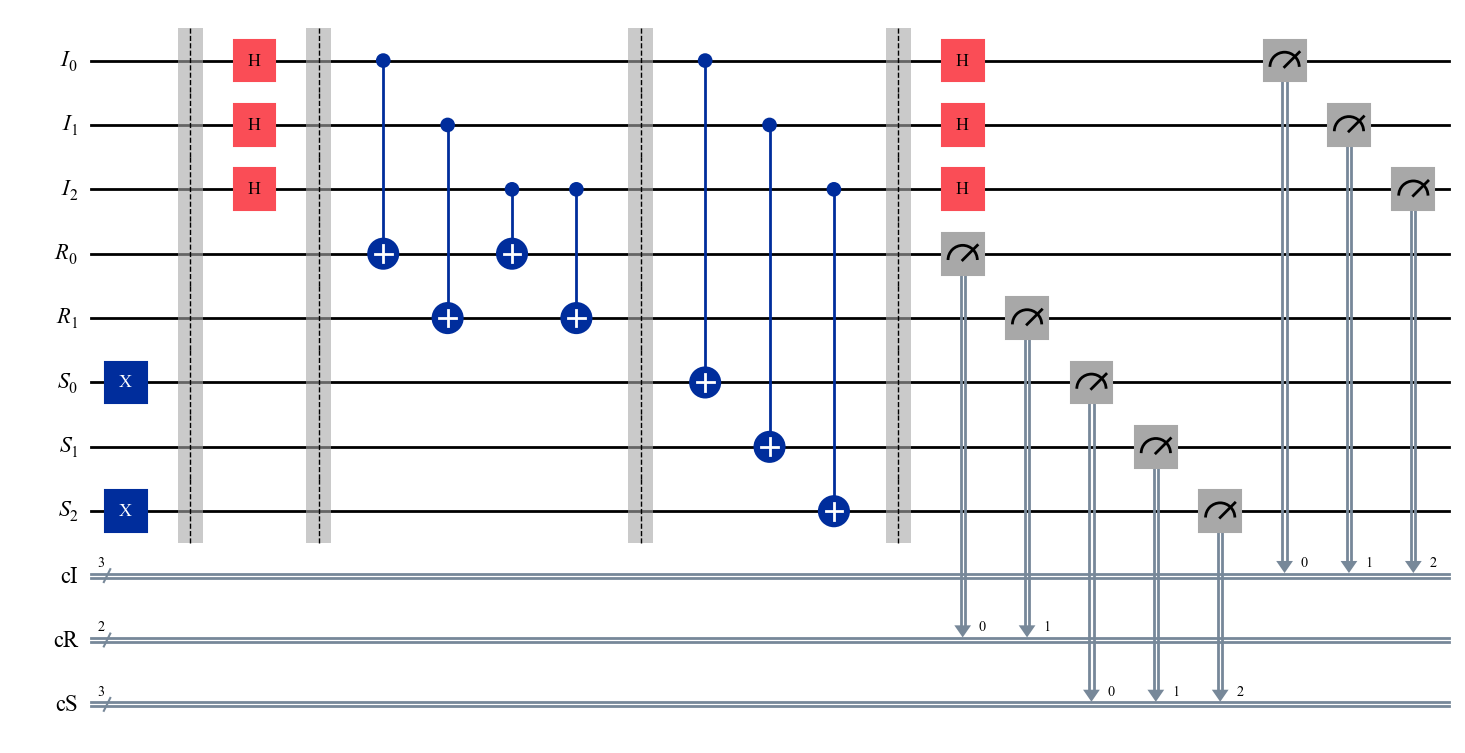


Block 2/2
Key matrix B_2:
[[1 1 1]
 [1 0 0]]


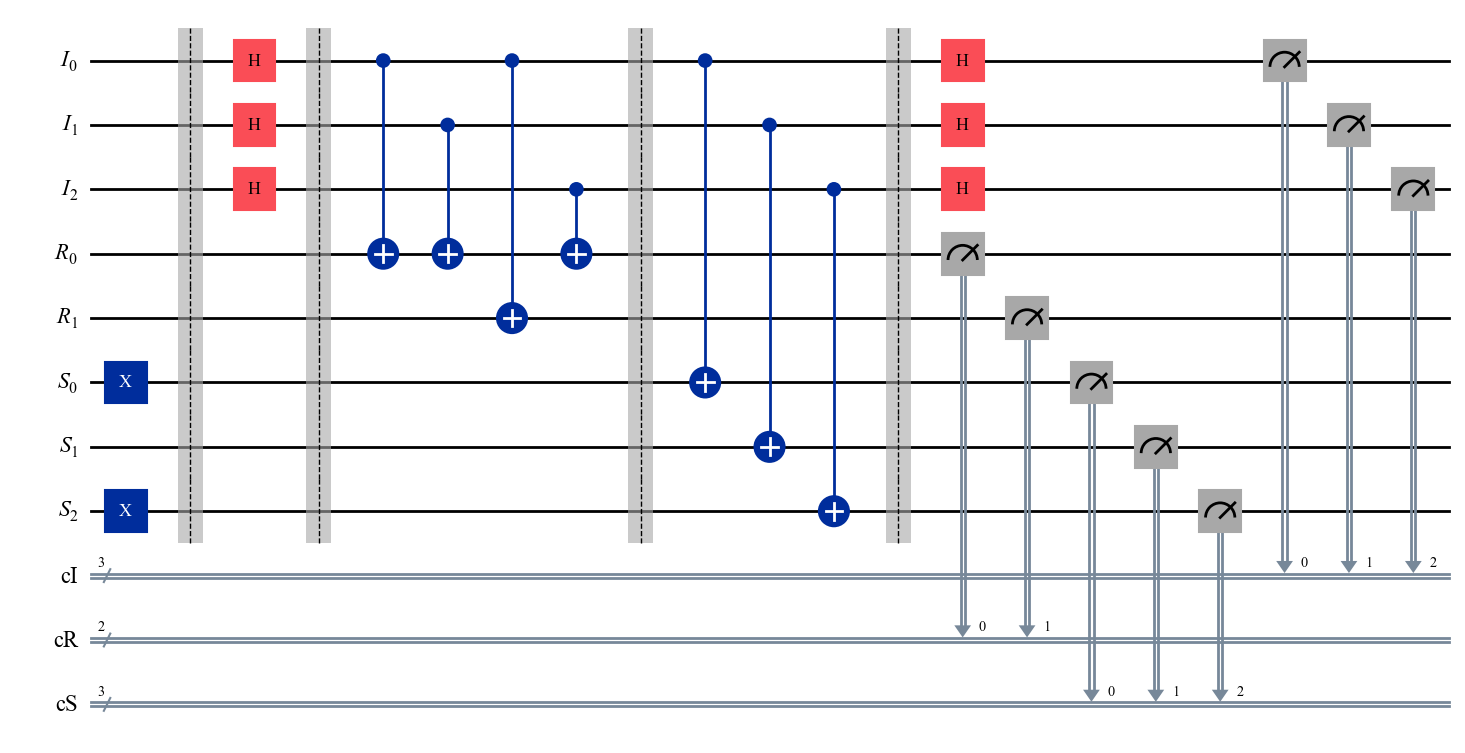

In [82]:
print("XOR permutation family:")
display(model.permutation_table(input_x=X))

for j in range(model.nu):
    print(f"\nBlock {j + 1}/{model.nu}")
    print(f"Key matrix B_{j + 1}:")
    print(model.get_key(j))

    qc = model.circuit(
        x=X,
        block=j,
        measure=True,
        barriers=True,
    )

    display(qc.draw(output="mpl", fold=-1))


## Independent block execution and input reuse

The keyed linear-tag construction consists of multiple
independently keyed circuit executions.

Every block receives a freshly prepared copy of the
same computational-basis input $\(x\)$.

For each block $\(j\)$, the measurement outcomes satisfy

$$
Y_j=x\oplus T_j,
\qquad
R_j=B_jT_j.
$$

The authorized decoder computes

$$
c_j=R_j\oplus B_jY_j=B_jx.
$$

Therefore, all blocks provide linear equations involving
the same unknown input.


In [83]:
# One quantum execution per block, with the SAME original input.
records = model.quantum_sample_all_blocks(
    x=X,
    seed=123,
)

for j, z in enumerate(records):
    B = model.get_key(j)

    # Recover the linear equation contributed by block j.
    c_j = z.r ^ tag_value(B, z.y, model.n)

    # Independently evaluate the expected equation B_j x.
    expected = tag_value(B, X, model.n)

    print(f"\nBlock {j + 1}")
    print(f"Block matrix B_{j + 1}: {model.get_key(j)}")
    print(f"Original input:  {X:0{model.n}b}")
    print(f"System output:   {z.y:0{model.n}b}")
    print(f"Measured tag:    {z.r:0{model.s}b}")
    print(f"Computed B_j x:  {c_j:0{model.s}b}")
    print(f"Expected B_j x:  {expected:0{model.s}b}")

    assert c_j == expected

# Attempt authorized decoding.
recovered = model.decode(records)

print("\nOriginal input:", f"{X:03b}")
print("Recovered input:", f"{recovered:03b}")

if model.resources["full_column_rank"]:
    assert recovered == X
else:
    print("Unique recovery is unavailable: rank(A) < n.")


Block 1
Block matrix B_1: [[1 0 1]
 [0 1 1]]
Original input:  101
System output:   011
Measured tag:    01
Computed B_j x:  10
Expected B_j x:  10

Block 2
Block matrix B_2: [[1 1 1]
 [1 0 0]]
Original input:  101
System output:   001
Measured tag:    01
Computed B_j x:  10
Expected B_j x:  10

Original input: 101
Recovered input: 101


In [84]:
# Usage example of quantum execution and classical sampling 
classical_records = model.sample_all_blocks(
    x=X,
    seed=456,
)

quantum_records = model.quantum_sample_all_blocks(
    x=X,
    seed=789,
)

print(f"Original input: |{X:0{model.n}b}>")

for j, (classical, quantum) in enumerate(
    zip(classical_records, quantum_records)
):
    c = classical.as_bitstrings(
        m=model.m, s=model.s, n=model.n
    )

    q = quantum.as_bitstrings(
        m=model.m, s=model.s, n=model.n
    )

    print(f"\nBlock {j + 1}")
    print(f"Classical: I={c['i']}  R={c['r']}  Y={c['y']}")
    print(f"Quantum:   I={q['i']}  R={q['r']}  Y={q['y']}")

Original input: |101>

Block 1
Classical: I=010  R=10  Y=111
Quantum:   I=001  R=10  Y=111

Block 2
Classical: I=111  R=10  Y=110
Quantum:   I=110  R=01  Y=001


## Proposition 4 — Exact classical transcript sampling

### Objective

We verify that the keyed linear-tag quantum circuit and the
classical sampler produce identical measurement distributions.

For a fixed input $\(x\)$ and secret matrix $\(B_j\)$, the paper
establishes

$$
P(i,r,y\mid x,B_j)
=
2^{-2n}\mathbf{1}_{\{r=B_j(x\oplus y)\}}.
$$

The support of the distribution is therefore

$$
|\operatorname{supp}(P_j)|=2^{2n},
$$

because the index outcome $\(i\)$ and system outcome $\(y\)$
can each assume $\(2^n\)$ values, while the tag $\(r\)$ is
uniquely determined.

We compare three independently obtained distributions:

1. **Theoretical:** probabilities computed from the equation.
2. **Quantum:** probabilities obtained from amplitudes of the State Vector.
3. **Classical:** probabilities obtained by the classical sampling algorithm.

The comparison uses total variation distance:

$$
D_{\mathrm{TV}}(P,Q)
=\frac12\sum_z|P(z)-Q(z)|.
$$

Proposition 4 predicts a distance of zero between all three
distributions in the ideal model.

Note: This experiment does not perform finite-shot sampling.

In [85]:
def total_variation(p: dict, q: dict) -> float:
    """Compute total variation distance between two distributions."""
    outcomes = set(p) | set(q)

    return 0.5 * sum(
        abs(p.get(z, 0.0) - q.get(z, 0.0))
        for z in outcomes
    )


def normalize_counts(counts: dict) -> dict:
    """Convert observed counts into empirical probabilities."""
    total = sum(counts.values())

    if total == 0:
        raise ValueError("Cannot normalize an empty sample.")

    return {
        outcome: count / total
        for outcome, count in counts.items()
    }


def theoretical_distribution(
    model: KeyedLinearTagModel,
    x: int,
    block: int = 0,
) -> dict[Transcript, float]:
    """Evaluate the exact transcript distribution from Eq. (10).

    This implementation uses the analytical formula directly
    and does not call either sampling or simulation method.

    The function requires the paper-exact XOR construction.
    """
    if not model.paper_exact:
        raise ValueError("The paper-exact model is required.")

    B = model.get_key(block)
    probabilities = {}

    for y in range(2**model.n):
        t = x ^ y
        r = tag_value(B, t, model.n)

        for i in range(2**model.n):
            z = Transcript(i=i, r=r, y=y)
            probabilities[z] = 2**(-2 * model.n)

    return probabilities

In [86]:
TOLERANCE = 1e-12

exact_results = []

# Store each block's distribution for later joint analysis.
theory_by_block = []
quantum_by_block = []
classical_by_block = []

for j in range(model.nu):

    # Compute the exact distributions of block j.
    p_theory = theoretical_distribution(model, X, j)
    p_quantum = model.quantum_probabilities(X, j)
    p_classical = model.classical_probabilities(X, j)

    # Preserve the distributions for subsequent experiments.
    theory_by_block.append(p_theory)
    quantum_by_block.append(p_quantum)
    classical_by_block.append(p_classical)

    # Compare the complete transcript distributions.
    tv_q_theory = total_variation(p_quantum, p_theory)
    tv_c_theory = total_variation(p_classical, p_theory)
    tv_q_c = total_variation(p_quantum, p_classical)

    # A block passes only if all three distances are negligible.
    match = all(
        distance <= TOLERANCE
        for distance in (tv_q_theory, tv_c_theory, tv_q_c)
    )

    exact_results.append({
        "Block": j + 1,
        "Rank(B)": gf2_rank(model.get_key(j)),
        "Support size": len(p_theory),
        "TV(Q, Theory)": tv_q_theory,
        "TV(C, Theory)": tv_c_theory,
        "TV(Q, C)": tv_q_c,
        "Match": match,
    })

# Display the results for all independently keyed blocks.
exact_df = pd.DataFrame(exact_results)

display(exact_df)

# Report success only if every block passes all comparisons.
if exact_df["Match"].all():
    print(
        "SUCCESS: All blocks reproduce the exact "
        "transcript distribution of Proposition 4."
    )
else:
    failed_blocks = exact_df.loc[
        ~exact_df["Match"], "Block"
    ].tolist()

    raise AssertionError(
        f"Proposition 4 verification failed "
        f"for blocks: {failed_blocks}"
    )

,Block,Rank(B),Support size,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)",Match
0,1,2,64,4.440892e-16,0.0,4.440892e-16,True
1,2,2,64,4.440892e-16,0.0,4.440892e-16,True


SUCCESS: All blocks reproduce the exact transcript distribution of Proposition 4.


The complete construction consists of $\nu$ independently
executed blocks, each using the same original input $x$ and
its corresponding secret matrix $B_j$.

The complete measurement transcript is

$$
\mathbf Z_\nu=(Z_1,\ldots,Z_\nu).
$$

Conditioned on the fixed input and all secret keys, the
individual block transcripts are independent. Therefore,

$$
P(\mathbf Z_\nu\mid x,k)
=
\prod_{j=1}^{\nu}P(Z_j\mid x,B_j).
$$

The single-block equivalence of Proposition 4 consequently
extends to the complete joint transcript distribution:

$$
P_{\mathrm Q}(\mathbf Z_\nu\mid x,k)
=
P_{\mathrm C}(\mathbf Z_\nu\mid x,k).
$$

This is a consequence of Proposition 4 and the independent
block execution model, rather than a separate numbered
proposition in the paper.

The joint distribution has $2^{2n\nu}$ nonzero-probability
outcomes. Explicit enumeration is therefore restricted to
small configurations.

In [87]:
from itertools import product
from math import prod


def joint_distribution(distributions, max_outcomes=20_000):
    """Construct the exact joint distribution of independent blocks.

    Parameters
    ----------
    distributions : list[dict]
        Exact probability distributions of individual blocks.
        Each dictionary maps a Transcript to its probability.
    max_outcomes : int
        Maximum number of joint outcomes to enumerate.

    Returns
    -------
    dict
        Joint probability distribution whose keys are tuples
        of Transcripts, ordered by block.

    Notes
    -----
    The product factorization holds conditional on the fixed
    input x and all fixed secret key matrices.
    """

    # Remove numerically negligible probabilities that may
    # appear in the quantum Statevector calculation.
    distributions = [
        {
            z: float(p)
            for z, p in dist.items()
            if p > 1e-14
        }
        for dist in distributions
    ]

    # Calculate the number of possible joint outcomes.
    support_size = prod(
        len(dist)
        for dist in distributions
    )

    if support_size > max_outcomes:
        raise ValueError(
            f"Joint support contains {support_size:,} outcomes; "
            f"the maximum allowed is {max_outcomes:,}."
        )

    # Enumerate all combinations of individual-block outcomes.
    joint = {}

    for combination in product(
        *(dist.items() for dist in distributions)
    ):

        # The complete transcript is (Z_1, ..., Z_nu).
        records = tuple(
            outcome
            for outcome, _ in combination
        )

        # Independence gives the product of probabilities.
        probability = prod(
            p
            for _, p in combination
        )

        joint[records] = probability

    return joint

In [88]:
JOINT_LIMIT = 20_000
TOLERANCE = 1e-12

joint_support_size = 2 ** (2 * model.n * model.nu)

print(f"Original input: |{X:0{model.n}b}>")
print(f"Number of blocks: {model.nu}")
print(f"Support per block: {2 ** (2 * model.n):,}")
print(f"Complete transcript support: {joint_support_size:,}")

# Set to None if exact joint enumeration is not feasible.
p_joint_theory = None
p_joint_quantum = None
p_joint_classical = None

if joint_support_size <= JOINT_LIMIT:

    # Construct exact joint distributions.
    p_joint_theory = joint_distribution(
        theory_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    p_joint_quantum = joint_distribution(
        quantum_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    p_joint_classical = joint_distribution(
        classical_by_block,
        max_outcomes=JOINT_LIMIT,
    )

    # Compare the three complete probability distributions.
    joint_results = {
        "Quantum vs theoretical": total_variation(
            p_joint_quantum,
            p_joint_theory,
        ),
        "Classical vs theoretical": total_variation(
            p_joint_classical,
            p_joint_theory,
        ),
        "Quantum vs classical": total_variation(
            p_joint_quantum,
            p_joint_classical,
        ),
    }

    display(
        pd.DataFrame(
            joint_results.items(),
            columns=["Comparison", "TV distance"],
        )
    )

    # Validate the normalization of each joint distribution.
    for p in (
        p_joint_theory,
        p_joint_quantum,
        p_joint_classical,
    ):
        assert np.isclose(
            sum(p.values()),
            1.0,
            atol=TOLERANCE,
        )

    # Print success only if every comparison actually passes.
    if all(
        distance <= TOLERANCE
        for distance in joint_results.values()
    ):
        print(
            "SUCCESS: All exact joint transcript "
            "distributions match."
        )
    else:
        raise AssertionError(
            "Proposition 4: joint distribution mismatch."
        )

else:
    print(
        "SKIPPED: Explicit joint distribution enumeration "
        "exceeds the configured limit."
    )
    print(
        "Joint equivalence follows from the per-block "
        "equalities and conditional independence, "
        "but was not enumerated numerically."
    )

Original input: |101>
Number of blocks: 2
Support per block: 64
Complete transcript support: 4,096


,Comparison,TV distance
0,Quantum vs theoretical,8.881784e-16
1,Classical vs theoretical,0.000000e+00
2,Quantum vs classical,8.881784e-16


SUCCESS: All exact joint transcript distributions match.



### Finite-shot quantum and classical sampling

After verifying the exact distribution identity of Proposition 4,
we investigate its behavior under finite-shot sampling.

We compare two sampling procedures:

- **Quantum sampling:** execution of the keyed quantum circuit
  using the Qiskit Aer simulator.
- **Classical sampling:** execution of the efficient classical
  algorithm established by Proposition 4.

Both procedures use the same original input $x$ and the same
fixed key matrix $B_j$ for each block.

Given $N$ measurement shots, empirical probabilities are
estimated by relative frequencies:

$$
\widehat P_j(z)
=
\frac{N_j(z)}{N}.
$$

We quantify their agreement through total variation distance:

$$
D_{\mathrm{TV}}(P,Q)
=
\frac{1}{2}\sum_z |P(z)-Q(z)|.
$$

Unlike exact probability comparisons, finite-shot distances
are generally nonzero due to statistical sampling fluctuations.

Repeated shots with fixed keys are used only to estimate the
distributions, not to test the fresh-key inversion-security
experiment.


In [89]:
SHOTS = 20000

sampling_results = []
sampling_by_block = {}

for j in range(model.nu):

    # The exact theoretical distribution of block j.
    p_theory = theory_by_block[j]

    # Quantum circuit sampling using Qiskit Aer.
    q_counts = model.quantum_counts(
        x=X,
        block=j,
        shots=SHOTS,
        seed=1000 + j,
    )

    # Efficient classical sampling from Proposition 4.
    c_counts = model.classical_counts(
        x=X,
        block=j,
        shots=SHOTS,
        seed=2000 + j,
    )

    # Check the number of generated measurement outcomes.
    assert sum(q_counts.values()) == SHOTS
    assert sum(c_counts.values()) == SHOTS

    # Check that all sampled outcomes satisfy the theoretical support.
    assert set(q_counts).issubset(p_theory)
    assert set(c_counts).issubset(p_theory)

    # Convert measurement counts to empirical probabilities.
    p_q = normalize_counts(q_counts)
    p_c = normalize_counts(c_counts)

    # Compute empirical total variation distances.
    tv_q_theory = total_variation(p_q, p_theory)
    tv_c_theory = total_variation(p_c, p_theory)
    tv_q_c = total_variation(p_q, p_c)

    sampling_results.append({
        "Block": j + 1,
        "Shots": SHOTS,
        "TV(Q, Theory)": tv_q_theory,
        "TV(C, Theory)": tv_c_theory,
        "TV(Q, C)": tv_q_c,
    })

    # Save data for subsequent visualizations.
    sampling_by_block[j] = {
        "theory": p_theory,
        "quantum": p_q,
        "classical": p_c,
    }

# Display individual-block results.
sampling_df = pd.DataFrame(sampling_results)

display(sampling_df)

print(f"Input: |{X:0{model.n}b}>")
print(f"Number of blocks: {model.nu}")
print(f"Shots per block: {SHOTS:,}")
print(f"Total circuit executions: {model.nu * SHOTS:,}")
print("All sampled outcomes satisfy the theoretical support.")

,Block,Shots,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)"
0,1,20000,0.023200,0.021650,0.03295
1,2,20000,0.020125,0.022775,0.03290


Input: |101>
Number of blocks: 2
Shots per block: 20,000
Total circuit executions: 40,000
All sampled outcomes satisfy the theoretical support.


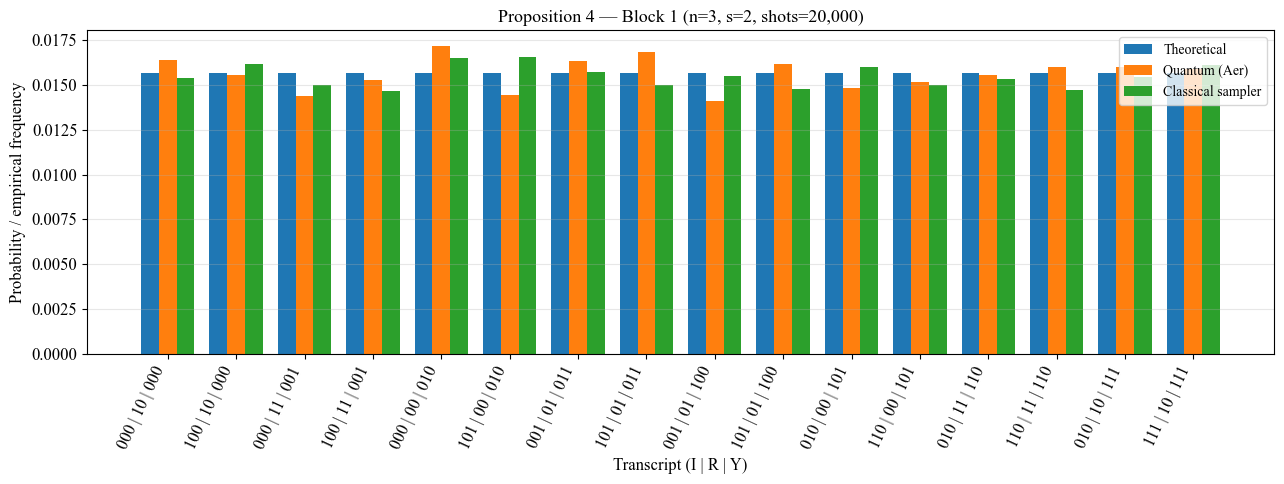

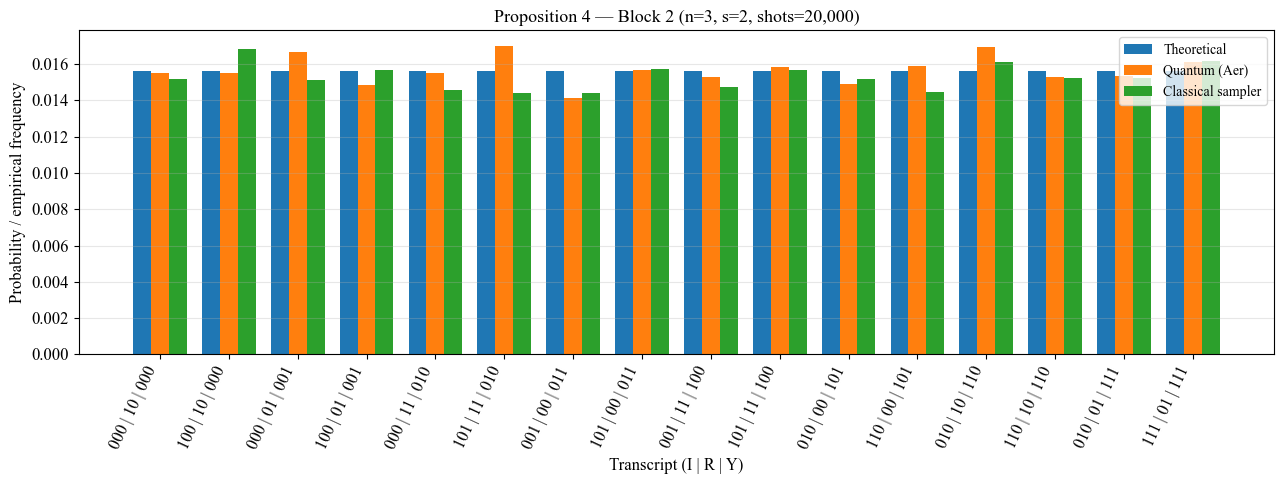

In [90]:
MAX_DISPLAY_OUTCOMES = 16

for j in range(model.nu):

    # Retrieve the distributions of the current block.
    distributions = sampling_by_block[j]

    p_theory = distributions["theory"]
    p_quantum = distributions["quantum"]
    p_classical = distributions["classical"]

    # Sort all theoretically valid measurement outcomes.
    outcomes = sorted(
        p_theory,
        key=lambda z: (z.y, z.i, z.r),
    )

    # Select evenly spaced outcomes for a readable plot.
    num_display = min(MAX_DISPLAY_OUTCOMES, len(outcomes))

    indices = np.linspace(
        0,
        len(outcomes) - 1,
        num=num_display,
        dtype=int,
    )

    selected = [outcomes[k] for k in indices]

    # Represent all registers as computational-basis bitstrings.
    labels = [
        (
            f"{z.i:0{model.m}b} | "
            f"{z.r:0{model.s}b} | "
            f"{z.y:0{model.n}b}"
        )
        for z in selected
    ]

    # Extract theoretical and empirical probabilities.
    theoretical_values = [
        p_theory[z]
        for z in selected
    ]

    quantum_values = [
        p_quantum.get(z, 0.0)
        for z in selected
    ]

    classical_values = [
        p_classical.get(z, 0.0)
        for z in selected
    ]

    # Create the grouped bar chart.
    positions = np.arange(len(selected))
    bar_width = 0.26

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.bar(
        positions - bar_width,
        theoretical_values,
        width=bar_width,
        label="Theoretical",
    )

    ax.bar(
        positions,
        quantum_values,
        width=bar_width,
        label="Quantum (Aer)",
    )

    ax.bar(
        positions + bar_width,
        classical_values,
        width=bar_width,
        label="Classical sampler",
    )

    # Format axes and labels.
    ax.set_xticks(positions)
    ax.set_xticklabels(
        labels,
        rotation=65,
        ha="right",
    )

    ax.set_xlabel("Transcript (I | R | Y)")
    ax.set_ylabel("Probability / empirical frequency")

    ax.set_title(
        f"Proposition 4 — Block {j + 1} "
        f"(n={model.n}, s={model.s}, shots={SHOTS:,})"
    )

    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

In [91]:
SHOT_VALUES = [256, 512, 1024, 2048, 4096, 8192, 16384]

convergence_results = []

for shots in SHOT_VALUES:
    for j in range(model.nu):

        # Exact theoretical distribution for block j.
        p_theory = theory_by_block[j]

        # Quantum circuit simulation using Qiskit Aer.
        q_counts = model.quantum_counts(
            x=X,
            block=j,
            shots=shots,
            seed=10000 + 100 * j + shots,
        )

        # Classical sampler from Proposition 4.
        c_counts = model.classical_counts(
            x=X,
            block=j,
            shots=shots,
            seed=20000 + 100 * j + shots,
        )

        assert sum(q_counts.values()) == shots
        assert sum(c_counts.values()) == shots
        assert set(q_counts).issubset(p_theory)
        assert set(c_counts).issubset(p_theory)

        p_q = normalize_counts(q_counts)
        p_c = normalize_counts(c_counts)

        convergence_results.append({
            "Shots": shots,
            "Block": j + 1,
            "TV(Q, Theory)": total_variation(p_q, p_theory),
            "TV(C, Theory)": total_variation(p_c, p_theory),
            "TV(Q, C)": total_variation(p_q, p_c),
        })

convergence_df = pd.DataFrame(convergence_results)

display(convergence_df)

,Shots,Block,"TV(Q, Theory)","TV(C, Theory)","TV(Q, C)"
0,256,1,0.195312,0.164062,0.277344
1,256,2,0.179688,0.179688,0.269531
2,512,1,0.138672,0.144531,0.197266
3,512,2,0.136719,0.125000,0.183594
4,1024,1,0.100586,0.111328,0.138672
5,1024,2,0.107422,0.099609,0.159180
6,2048,1,0.069336,0.068359,0.098633
7,2048,2,0.060059,0.066406,0.082031
8,4096,1,0.047607,0.049316,0.065918
9,4096,2,0.050781,0.055176,0.081543


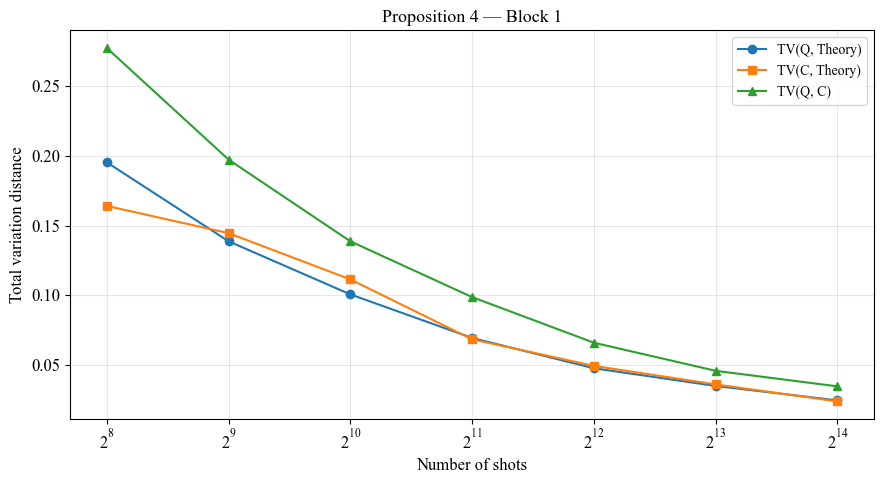

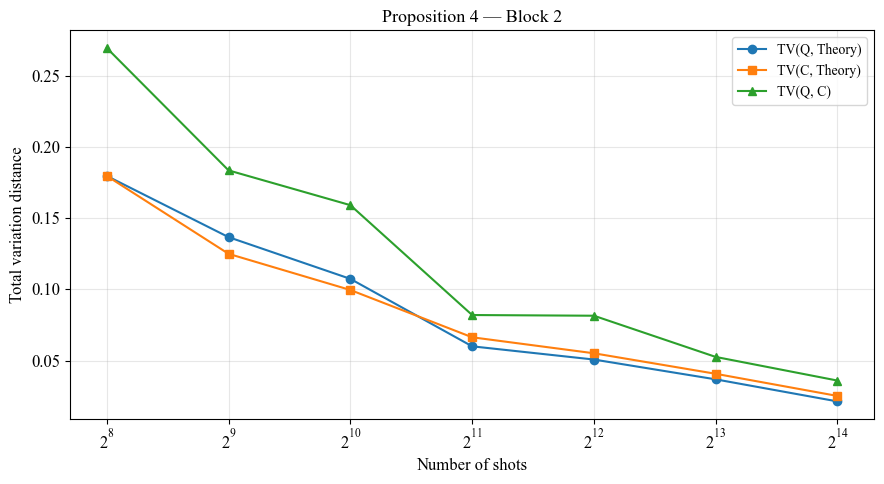

In [92]:
for j in range(model.nu):

    block_df = convergence_df[
        convergence_df["Block"] == j + 1
    ].sort_values("Shots")

    fig, ax = plt.subplots(figsize=(9, 5))

    for column, marker in [
        ("TV(Q, Theory)", "o"),
        ("TV(C, Theory)", "s"),
        ("TV(Q, C)", "^"),
    ]:
        ax.plot(
            block_df["Shots"],
            block_df[column],
            marker=marker,
            label=column,
        )

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Number of shots")
    ax.set_ylabel("Total variation distance")
    ax.set_title(f"Proposition 4 — Block {j + 1}")

    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


## Proposition 5 — Authorized decoding

We now investigate the authorized decoding procedure described
in Section IV of the paper. The objective is to verify that the authorized decoder can
recover the original computational-basis input from the
measurement transcripts of all keyed blocks.

For every independently keyed block $j$, the measurement
transcript is

$$
Z_j=(I_j,R_j,Y_j).
$$

The authorized decoder knows the secret matrix $B_j$ and
computes

$$
c_j=R_j\oplus B_jY_j.
$$

From the linear-tag measurement relation,

$$
R_j=B_j(x\oplus Y_j),
$$

we obtain

$$
c_j=B_j(x\oplus Y_j)\oplus B_jY_j=B_jx.
$$

Combining all $\nu$ blocks gives the binary linear system

$$
A=
\begin{pmatrix}
B_1\\
B_2\\
\vdots\\
B_\nu
\end{pmatrix},
\qquad
c=
\begin{pmatrix}
c_1\\
c_2\\
\vdots\\
c_\nu
\end{pmatrix},
\qquad
Ax=c.
$$

Here $A$ is a $(\nu s)\times n$ binary matrix.

**Proposition 5** states that if

$$
\operatorname{rank}_{\mathbb F_2}(A)=n,
$$

the authorized decoder recovers the original input $x$
with probability one in the ideal circuit model.

The decoder solves $Ax=c$ using Gaussian elimination over
$\mathbb F_2$, without requiring the explicit construction
of a left inverse.

If $A$ is rank deficient, the decoder reports failure.


In [93]:
# PROPOSITION 5 — AUTHORIZED QUANTUM DECODING

quantum_records = [
    next(iter(model.quantum_counts(
        x=X, block=j, shots=1, seed=5000 + j
    )))
    for j in range(model.nu)
]

A = np.vstack([model.get_key(j) for j in range(model.nu)])
rank_A = gf2_rank(A)

rows = []

for j, z in enumerate(quantum_records):
    B = model.get_key(j)
    c_j = z.r ^ tag_value(B, z.y, model.n)
    expected = tag_value(B, X, model.n)

    assert c_j == expected

    rows.append({
        "Block": j + 1,
        "I": f"{z.i:0{model.n}b}",
        "R": f"{z.r:0{model.s}b}",
        "Y": f"{z.y:0{model.n}b}",
        "c_j": f"{c_j:0{model.s}b}",
        "B_j x": f"{expected:0{model.s}b}",
    })

display(pd.DataFrame(rows))

recovered = model.decode(quantum_records)

print(f"Original input: |{X:0{model.n}b}>")
print(f"Rank(A): {rank_A}/{model.n}")

if rank_A == model.n:
    assert recovered == X
    print(f"SUCCESS: Recovered |{recovered:0{model.n}b}>")
else:
    assert recovered is None
    print("Decoding failed: A is rank deficient.")

,Block,I,R,Y,c_j,B_j x
0,1,001,10,000,10,10
1,2,111,01,111,10,10


Original input: |101>
Rank(A): 3/3
SUCCESS: Recovered |101>



### Authorized decoding across all computational-basis inputs

The previous experiment demonstrated authorized recovery for a
single computational-basis input.

We now test all $2^n$ possible inputs while keeping the
secret key matrices fixed.

For each input $x$, every keyed quantum block is executed
once, producing a complete transcript

$$
\mathbf Z_\nu=(Z_1,\ldots,Z_\nu).
$$

The decoder reconstructs the system $Ax=c$ and attempts
to recover the original input.

According to Proposition 5, full column rank guarantees

$$
\operatorname{rank}_{\mathbb F_2}(A)=n
\quad\Longrightarrow\quad
\hat{x}=x.
$$

This experiment verifies the prediction on one quantum
measurement transcript for each possible input. The
proposition itself guarantees recovery for every valid
transcript when the rank condition is satisfied.


In [94]:
results = []

for x in range(2**model.n):

    # Execute each quantum block once on the same input x.
    records = [
        next(iter(model.quantum_counts(
            x=x,
            block=j,
            shots=1,
            seed=10000 + 100*x + j,
        )))
        for j in range(model.nu)
    ]

    # Authorized decoding over GF(2).
    recovered = model.decode(records)

    # Determine the expected behavior from the key rank.
    if rank_A == model.n:
        passed = recovered == x
    else:
        passed = recovered is None

    results.append({
        "Input": f"{x:0{model.n}b}",
        "Recovered": (
            f"{recovered:0{model.n}b}"
            if recovered is not None else "Failure"
        ),
        "Correct": passed,
    })

input_df = pd.DataFrame(results)
display(input_df)

if input_df["Correct"].all():
    print("SUCCESS: All tested inputs behave as predicted by Proposition 5.")
else:
    raise AssertionError("Authorized decoding verification failed.")

,Input,Recovered,Correct
0,000,000,True
1,001,001,True
2,010,010,True
3,011,011,True
4,100,100,True
5,101,101,True
6,110,110,True
7,111,111,True


SUCCESS: All tested inputs behave as predicted by Proposition 5.



### Decoding failure 

The authorized decoding experiments showed that the original
input is recovered whenever the stacked secret-key matrix
has full column rank.

For a fixed key realization, the decoding condition is

$$
\operatorname{rank}_{\mathbb F_2}(A)=n.
$$

If this condition is not satisfied, the system

$$
Ax=c
$$

does not uniquely determine the input. Indeed, a rank-deficient
matrix has a nonzero kernel vector $v$ such that

$$
Av=0.
$$

Therefore, two different inputs $x$ and $x\oplus v$ produce
the same decoding information:

$$
A(x\oplus v)=Ax.
$$

We first demonstrate this ambiguity using an explicitly
rank-deficient key configuration.

We then investigate how often rank deficiency occurs when
the secret keys are independently and uniformly generated.

Corollary 1 establishes

$$
\epsilon_{\mathrm{corr}}
=
\Pr[\operatorname{rank}_{\mathbb F_2}(A)<n]
\leq
\frac{2^n-1}{2^{\nu s}}.
$$

The probability is taken over fresh random key generation,
not over repeated measurements with a single fixed key.

The first experiment illustrates the mechanism of failure.
The second estimates its probability through Monte Carlo.


In [95]:
B1 = np.array([
    [1, 0, 0],
    [0, 1, 0],
], dtype=np.uint8)

B2 = np.array([
    [1, 1, 0],
    [0, 1, 0],
], dtype=np.uint8)

bad_model = KeyedLinearTagModel(
    n=3,
    s=2,
    nu=2,
    key_matrices=np.stack([B1, B2]),
)

A_bad = np.vstack([B1, B2])
rank_bad = gf2_rank(A_bad)

print("Stacked key matrix A:")
print(A_bad)
print(f"Rank(A): {rank_bad}/{bad_model.n}")

inputs = [0b001, 0b101]

for x in inputs:

    # One quantum execution per block.
    records = [
        next(iter(bad_model.quantum_counts(
            x=x, block=j, shots=1, seed=700 + j + x
        )))
        for j in range(bad_model.nu)
    ]

    # Reconstruct the syndrome of each block.
    syndromes = [
        z.r ^ tag_value(bad_model.get_key(j), z.y, bad_model.n)
        for j, z in enumerate(records)
    ]

    # Authorized decoder requires a unique solution.
    recovered = bad_model.decode(records)
    assert recovered is None

    # Find ALL inputs compatible with the measured syndromes.
    compatible_inputs = [
        candidate
        for candidate in range(2**bad_model.n)
        if all(
            tag_value(
                bad_model.get_key(j),
                candidate,
                bad_model.n,
            ) == syndromes[j]
            for j in range(bad_model.nu)
        )
    ]

    assert x in compatible_inputs
    assert len(compatible_inputs) == 2**(bad_model.n - rank_bad)

    print(f"\nOriginal input: |{x:03b}>")
    print("Recovered syndromes:", [f"{c:02b}" for c in syndromes])
    print(
        "Compatible inputs:",
        ", ".join(f"|{v:03b}>" for v in compatible_inputs)
    )
    print("Decoder result: FAILURE (non-unique solution)")

Stacked key matrix A:
[[1 0 0]
 [0 1 0]
 [1 1 0]
 [0 1 0]]
Rank(A): 2/3

Original input: |001>
Recovered syndromes: ['01', '01']
Compatible inputs: |001>, |101>
Decoder result: FAILURE (non-unique solution)

Original input: |101>
Recovered syndromes: ['01', '01']
Compatible inputs: |001>, |101>
Decoder result: FAILURE (non-unique solution)


In [96]:
from math import prod

N = model.n
S = model.s
TRIALS = 5000

NU_VALUES = range(
    max(1, (N - 2) // S),
    (N + 8) // S + 2,
)

rng = np.random.default_rng(2027)


def exact_rank_failure(n, r):
    """Exact probability that a uniform binary r-by-n
    matrix has rank smaller than n.
    """
    if r < n:
        return 1.0

    return 1.0 - prod(
        1.0 - 2.0**(i - r)
        for i in range(n)
    )


failure_rows = []

for nu in NU_VALUES:

    r = nu * S
    failures = 0

    for _ in range(TRIALS):

        # Generate a fresh stacked key matrix.
        A_random = rng.integers(
            0, 2,
            size=(r, N),
            dtype=np.uint8,
        )

        # The ideal decoder fails for rank-deficient keys.
        if gf2_rank(A_random) < N:
            failures += 1

    p_exact = exact_rank_failure(N, r)

    # Corollary 1 bound, capped at 1 for visualization.
    p_bound = min(1.0, (2**N - 1) / 2**r)

    assert p_exact <= p_bound + 1e-12

    failure_rows.append({
        "nu": nu,
        "nu*s": r,
        "Failures": failures,
        "Trials": TRIALS,
        "Empirical": failures / TRIALS,
        "Exact": p_exact,
        "Corollary 1": p_bound,
    })

failure_df = pd.DataFrame(failure_rows)

display(failure_df)

,nu,nu*s,Failures,Trials,Empirical,Exact,Corollary 1
0,1,2,5000,5000,1.0000,1.000000,1.000000
1,2,4,1866,5000,0.3732,0.384766,0.437500
2,3,6,544,5000,0.1088,0.105988,0.109375
3,4,8,137,5000,0.0274,0.027131,0.027344
4,5,10,34,5000,0.0068,0.006823,0.006836
5,6,12,9,5000,0.0018,0.001708,0.001709


In [97]:
def wilson_interval(k, trials, z=1.96):
    """Wilson confidence interval for a binomial proportion."""
    p = k / trials
    denominator = 1 + z**2 / trials
    center = (p + z**2 / (2 * trials)) / denominator

    half_width = (
        z * np.sqrt(
            p * (1 - p) / trials
            + z**2 / (4 * trials**2)
        ) / denominator
    )

    return max(0.0, center - half_width), min(
        1.0, center + half_width
    )

Saved: /Users/jackvittori/Desktop/ISCAS2027/res/corollary_1_decoding_failure.pdf


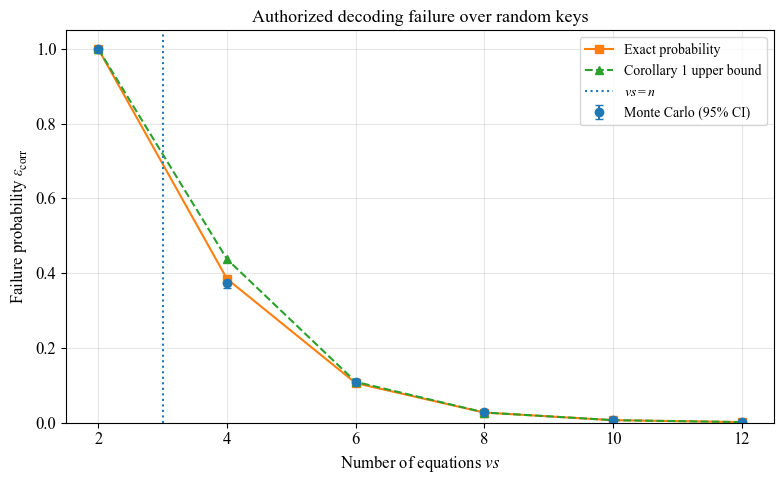

In [98]:
intervals = [
    wilson_interval(k, TRIALS)
    for k in failure_df["Failures"]
]

lower_errors = [
    p - interval[0]
    for p, interval in zip(failure_df["Empirical"], intervals)
]

upper_errors = [
    interval[1] - p
    for p, interval in zip(failure_df["Empirical"], intervals)
]

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    failure_df["nu*s"],
    failure_df["Empirical"],
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=3,
    label="Monte Carlo (95% CI)",
)

ax.plot(
    failure_df["nu*s"],
    failure_df["Exact"],
    "s-",
    label="Exact probability",
)

ax.plot(
    failure_df["nu*s"],
    failure_df["Corollary 1"],
    "^--",
    label="Corollary 1 upper bound",
)

ax.axvline(
    N,
    linestyle=":",
    label=r"$\nu s=n$",
)

ax.set_xticks(failure_df["nu*s"])
ax.set_xlabel(r"Number of equations $\nu s$")
ax.set_ylabel(r"Failure probability $\epsilon_{\mathrm{corr}}$")
ax.set_title("Authorized decoding failure over random keys")

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_pdf(fig, "corollary_1_decoding_failure")
plt.show()

### Interpretation of the decoding failure experiment

The experiment connects the conditional correctness
guarantee of Proposition 5 with the probabilistic
reliability guarantee of Corollary 1.

In the previous rank-deficient example, different inputs
produced the same syndrome, making unique recovery
impossible.

The Monte Carlo experiment now estimates how often such
rank-deficient configurations occur under independent
uniform key generation.

Two regimes can be distinguished:

- If $\nu s<n$, the matrix has fewer rows than columns,
  so full column rank is impossible and decoding fails.

- If $\nu s>n$, additional random equations reduce
  the probability of rank deficiency.

The empirical failure estimates approach the exact
rank-deficiency probabilities and are consistent with
the upper bound established by Corollary 1:

$$
\epsilon_{\mathrm{corr}}
\leq
\frac{2^n-1}{2^{\nu s}}.
$$

The error bars represent 95% Wilson confidence intervals
for the Monte Carlo estimates.

The theoretical upper bound applies to the true failure
probability, not necessarily to each finite-sample estimate.

In conclusion, Proposition 5 guarantees exact recovery
for full-rank key matrices, whereas Corollary 1 shows
that the probability of generating rank-deficient keys
decreases as the number of available equations grows.

These results establish authorized correctness and
reliability, not adversarial inversion security.

![Decoding failure](img/decoding-failure.png)

### Authorized decoding success probability

The previous experiment measured the probability that the
stacked key matrix is rank deficient.

We now consider the complementary event: successful
authorized decoding.

According to Proposition 5, the ideal decoder succeeds
if and only if the stacked matrix has full column rank.

Therefore,

$$
P_{\mathrm{success}}
=
\Pr[\operatorname{rank}_{\mathbb F_2}(A)=n]
=
1-\epsilon_{\mathrm{corr}}.
$$

Corollary 1 consequently provides the lower bound

$$
P_{\mathrm{success}}
\geq
\max\left\{
0,\,
1-\frac{2^n-1}{2^{\nu s}}
\right\}.
$$

The threshold $\nu s=n$ marks the point at which full-rank
decoding first becomes possible.

Beyond this threshold, increasing the number of available
tag equations improves the probability of successful
authorized recovery.

,nu*s,Empirical success,Exact success,Success lower bound
0,2,0.0000,0.000000,0.000000
1,4,0.6268,0.615234,0.562500
2,6,0.8912,0.894012,0.890625
3,8,0.9726,0.972869,0.972656
4,10,0.9932,0.993177,0.993164
5,12,0.9982,0.998292,0.998291


Saved: /Users/jackvittori/Desktop/ISCAS2027/res/corollary_1_decoding_success.pdf


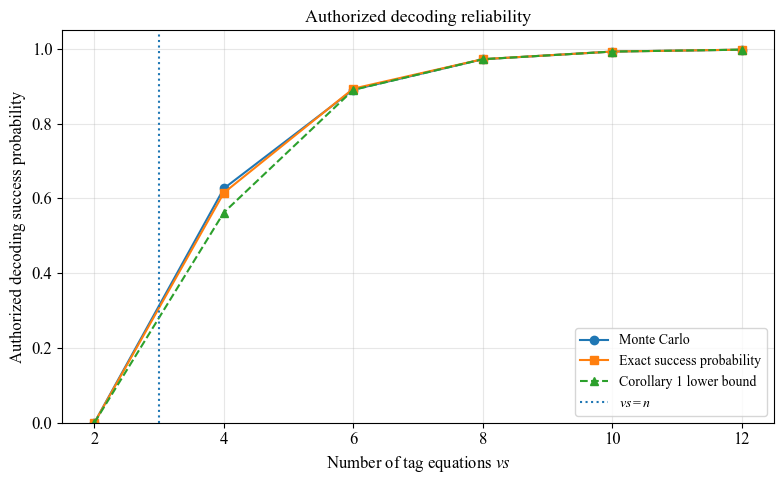

In [99]:
success_df = failure_df.copy()

success_df["Empirical success"] = 1 - success_df["Empirical"]
success_df["Exact success"] = 1 - success_df["Exact"]
success_df["Success lower bound"] = 1 - success_df["Corollary 1"]

display(success_df[[
    "nu*s",
    "Empirical success",
    "Exact success",
    "Success lower bound",
]])

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    success_df["nu*s"],
    success_df["Empirical success"],
    "o-",
    label="Monte Carlo",
)

ax.plot(
    success_df["nu*s"],
    success_df["Exact success"],
    "s-",
    label="Exact success probability",
)

ax.plot(
    success_df["nu*s"],
    success_df["Success lower bound"],
    "^--",
    label="Corollary 1 lower bound",
)

ax.axvline(
    N,
    linestyle=":",
    label=r"$\nu s=n$",
)

ax.set_xlabel(r"Number of tag equations $\nu s$")
ax.set_ylabel(r"Authorized decoding success probability")
ax.set_title("Authorized decoding reliability")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_pdf(fig, "corollary_1_decoding_success")
plt.show()

## Proposition 6 — Key-Averaged Transcript Distribution
The previous experiments established quantum-classical
distributional equivalence for fixed keys (Proposition 4)
and authorized input recovery when the stacked key matrix
has full column rank (Proposition 5).

We now investigate the observations available without
knowledge of the secret key.

For each Monte Carlo trial, a fresh independent uniformly
random matrix $B$ is generated, and its corresponding
Qiskit circuit is executed once on the fixed input $x$.

The measured pair $(R,Y)$ is recorded without using the
analytical key-averaged probability formula.

The empirical distribution is then compared with the
theoretical prediction:

$$
P(r,y\mid x)=
\begin{cases}
2^{-n}, & y=x,\ r=0,\\
0, & y=x,\ r\neq 0,\\
2^{-(n+s)}, & y\neq x.
\end{cases}
$$

The total variation distance measures the discrepancy
between observed frequencies and theoretical probabilities.

As the number of independently keyed circuit executions
increases, the empirical distribution is expected to
converge to the theoretical key-averaged channel.

This provides numerical evidence supporting the
key-averaged distribution derived from the construction.

Importantly, the channel is not perfectly hiding:
the event $Y=X$ necessarily produces $R=0$, and such
observations may reveal information about the input.

This experiment characterizes the observation channel
for one block. It does not yet establish the adversary's
multi-block inversion probability, which is addressed
by Proposition 7.

In [100]:
from collections import Counter
from qiskit_aer import AerSimulator

SEC_N = 3                  # Number of system/index qubits
SEC_S = 2                  # Number of tag qubits
SEC_X = 0b101              # Fixed computational-basis input

TRIALS = 2048              # Total independent random-key trials
N_CHECKPOINTS = 35         # Number of convergence checkpoints
MIN_CHECKPOINT = 32        # First checkpoint
BATCH_SIZE = 128           # Circuits submitted per simulator batch
SEED = 2027               # Reproducibility seed

assert 1 <= SEC_S <= SEC_N
assert 0 <= SEC_X < 2**SEC_N

CHECKPOINTS = np.unique(
    np.geomspace(
        min(MIN_CHECKPOINT, TRIALS),
        TRIALS,
        num=N_CHECKPOINTS,
    ).round().astype(int)
)

rng = np.random.default_rng(SEED)
simulator = AerSimulator()

observations = []

# ------------------------------------------------------------
# QUANTUM SAMPLING WITH FRESH RANDOM KEYS
# ------------------------------------------------------------

for start in range(0, TRIALS, BATCH_SIZE):

    circuits = []
    instances = []

    batch_size = min(BATCH_SIZE, TRIALS - start)

    for _ in range(batch_size):

        # Fresh independent uniform secret matrix.
        B = rng.integers(
            0, 2,
            size=(SEC_S, SEC_N),
            dtype=np.uint8,
        )

        instance = KeyedLinearTagModel(
            n=SEC_N,
            s=SEC_S,
            nu=1,
            key_matrices=B[None, :, :],
        )

        circuits.append(
            instance.circuit(
                x=SEC_X,
                block=0,
                measure=True,
            )
        )
        instances.append(instance)

    # Exactly one shot per independently keyed circuit.
    result = simulator.run(
        circuits,
        shots=1,
        seed_simulator=int(rng.integers(1, 2**31)),
    ).result()

    for k, instance in enumerate(instances):
        raw = next(iter(result.get_counts(k)))
        z = instance.parse_outcome(raw)

        observations.append((z.r, z.y))

# ------------------------------------------------------------
# THEORETICAL DISTRIBUTION 
# ------------------------------------------------------------

p_theory = {
    (r, y): (
        2**(-SEC_N) if y == SEC_X and r == 0
        else 0.0 if y == SEC_X
        else 2**(-SEC_N - SEC_S)
    )
    for y in range(2**SEC_N)
    for r in range(2**SEC_S)
}

# ------------------------------------------------------------
# EMPIRICAL CONVERGENCE
# ------------------------------------------------------------

results = []

for shots in CHECKPOINTS:

    counts = Counter(observations[:shots])

    p_empirical = {
        outcome: frequency / shots
        for outcome, frequency in counts.items()
    }

    results.append({
        "Trials": shots,
        "TV(Empirical, Theory)": total_variation(
            p_empirical,
            p_theory,
        ),
    })

convergence_security_df = pd.DataFrame(results)

display(convergence_security_df)

print(f"Input: |{SEC_X:0{SEC_N}b}>")
print(f"Independent circuit executions: {TRIALS:,}")
print(f"Number of checkpoints: {len(CHECKPOINTS)}")
print(f"Final TV distance: {results[-1]['TV(Empirical, Theory)']:.6f}")

,Trials,"TV(Empirical, Theory)"
0,32,0.281250
1,36,0.260417
2,41,0.287348
3,46,0.282609
4,52,0.264423
5,59,0.226165
6,67,0.196362
7,75,0.180417
8,85,0.158824
9,96,0.166667


Input: |101>
Independent circuit executions: 2,048
Number of checkpoints: 35
Final TV distance: 0.043457


Saved: /Users/jackvittori/Desktop/ISCAS2027/res/proposition_6_key_average_convergence.pdf


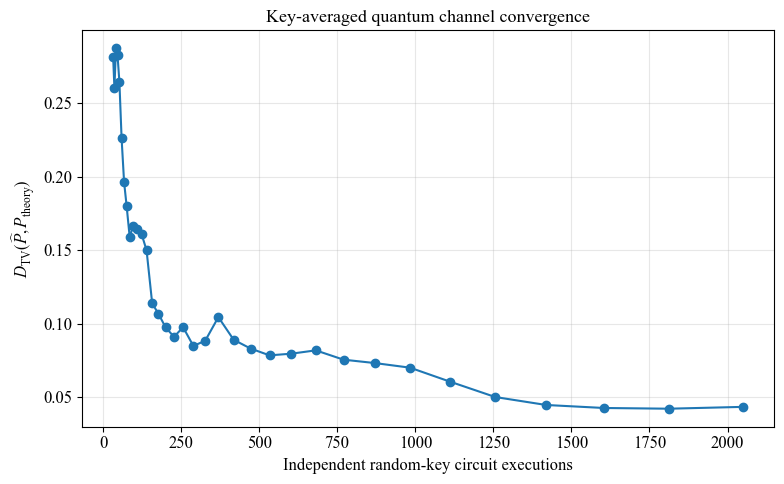

In [101]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    convergence_security_df["Trials"],
    convergence_security_df["TV(Empirical, Theory)"],
    marker="o",
)

ax.set_xlabel("Independent random-key circuit executions")
ax.set_ylabel(r"$D_{\mathrm{TV}}(\widehat{P},P_{\mathrm{theory}})$")
ax.set_title("Key-averaged quantum channel convergence")
ax.grid(alpha=0.3)

plt.tight_layout()
save_pdf(fig, "proposition_6_key_average_convergence")
plt.show()


## Proposition 7 — Adversarial Inversion Security

We now investigate the probability that an adversary can
recover the original input without knowing the secret
key matrices.

Unlike Proposition 5, where the authorized decoder knows
all matrices $B_j$, the adversary observes only the
measurement transcripts

$$
\mathbf Z_\nu=(Z_1,\ldots,Z_\nu).
$$

The input $X$ is uniformly distributed over $\mathbb F_2^n$.
Every block uses a fresh independent uniform secret key,
and each block is executed exactly once per challenge.

Proposition 7 establishes the inversion bound

$$
p_{\mathrm{guess}}(X\mid\mathbf Z_\nu)
\leq
\frac{2^s}{2^n-\nu}
+
\frac{\nu(\nu-1)}{2^{n+1}},
\qquad \nu<2^n.
$$

We experimentally estimate the success probability of
an optimal Bayesian adversary using the key-averaged
observation channel derived previously.

The adversary knows the public model parameters and the
observed transcripts, but not the actual secret keys.

We compare the empirical guessing probability with the
bound from Proposition 7.

The theoretical bound need not be tight.


In [102]:
# ============================================================
# PROPOSITION 7 — ADVERSARIAL INVERSION MONTE CARLO
# ============================================================

# Experiment parameters
ADV_N = 3
ADV_S = 2
ADV_NU = 2

TRIALS = 10000
N_CHECKPOINTS = 35
MIN_CHECKPOINT = 100
SEED = 2027

assert 1 <= ADV_S <= ADV_N
assert 1 <= ADV_NU < 2**ADV_N
assert TRIALS >= MIN_CHECKPOINT >= 1

rng = np.random.default_rng(SEED)


def adversarial_guess(tags, outputs, n, s, rng):
    """Bayes-optimal guess using only public observations.

    The adversary does not receive the secret key matrices.
    Scores are proportional to key-averaged likelihoods.
    """
    scores = np.zeros(2**n, dtype=int)
    excluded = np.zeros(2**n, dtype=bool)

    for r, y in zip(tags, outputs):

        if r == 0:
            # Candidate X=Y is 2^s times more likely.
            scores[y] += s
        else:
            # X=Y is impossible when the tag is nonzero.
            excluded[y] = True

    scores[excluded] = -10**9

    # Break equally likely candidates uniformly.
    candidates = np.flatnonzero(scores == scores.max())
    return int(rng.choice(candidates))


successes = []

for _ in range(TRIALS):

    # Uniform unknown input.
    x = int(rng.integers(0, 2**ADV_N))

    # Fresh independent secret keys for this challenge.
    keys = rng.integers(
        0, 2,
        size=(ADV_NU, ADV_S, ADV_N),
        dtype=np.uint8,
    )

    tags = []
    outputs = []

    for j in range(ADV_NU):

        # Proposition 4: exact ideal classical sampler.
        t = int(rng.integers(0, 2**ADV_N))

        y = x ^ t
        r = tag_value(keys[j], t, ADV_N)

        tags.append(r)
        outputs.append(y)

    # The adversary sees tags and outputs, not keys.
    guess = adversarial_guess(
        tags, outputs, ADV_N, ADV_S, rng
    )

    successes.append(int(guess == x))


CHECKPOINTS = np.unique(
    np.geomspace(
        MIN_CHECKPOINT,
        TRIALS,
        num=N_CHECKPOINTS,
    ).round().astype(int)
)

cumulative = np.cumsum(successes)

p_bound = (
    2**ADV_S / (2**ADV_N - ADV_NU)
    + ADV_NU * (ADV_NU - 1) / 2**(ADV_N + 1)
)

inversion_df = pd.DataFrame({
    "Trials": CHECKPOINTS,
    "Empirical guessing probability": [
        cumulative[k - 1] / k for k in CHECKPOINTS
    ],
    "Proposition 7 bound": min(1.0, p_bound),
    "Random guessing baseline": 2**(-ADV_N),
})

display(inversion_df)

print(f"Input dimension: n={ADV_N}")
print(f"Tag width: s={ADV_S}")
print(f"Independent blocks: nu={ADV_NU}")
print(f"Observed checkpoints: {len(CHECKPOINTS)}")
print(f"Empirical success: {np.mean(successes):.5f}")
print(f"Proposition 7 bound: {p_bound:.5f}")

,Trials,Empirical guessing probability,Proposition 7 bound,Random guessing baseline
0,100,0.220000,0.791667,0.125
1,115,0.243478,0.791667,0.125
2,131,0.236641,0.791667,0.125
3,150,0.233333,0.791667,0.125
4,172,0.244186,0.791667,0.125
5,197,0.263959,0.791667,0.125
6,225,0.257778,0.791667,0.125
7,258,0.259690,0.791667,0.125
8,296,0.266892,0.791667,0.125
9,338,0.275148,0.791667,0.125


Input dimension: n=3
Tag width: s=2
Independent blocks: nu=2
Observed checkpoints: 35
Empirical success: 0.27710
Proposition 7 bound: 0.79167



## Proposition 7 — Bayesian inversion attack

### Objective

We evaluate the ability of an adversary to recover a uniformly
random input $X$ from the measurement transcripts of the
keyed linear-tag construction.

Each challenge consists of $\nu$ independently keyed quantum
circuits, executed once on the same original input $X$.

The challenger generates fresh secret keys and executes
the actual Qiskit circuits. The adversary receives only

$$
\mathbf Z_\nu=(Z_1,\ldots,Z_\nu).
$$

The adversary does not receive $X$ or the key matrices.

### Attack strategy

We use a maximum a posteriori (MAP) adversary. It assigns
a posterior probability to every candidate input using the
key-averaged observation channel:

$$
P(X=x\mid\mathbf Z_\nu)
\propto
\prod_{j=1}^{\nu}P(R_j,Y_j\mid X=x).
$$

The adversary selects a candidate with the largest posterior
probability. Ties are resolved uniformly at random.

### Experimental evaluation

We repeat the complete inversion challenge independently
many times, generating new inputs and keys for every trial.

The empirical attack success probability is

$$
\widehat p_{\mathrm{guess}}
=
\frac{\text{Number of correct guesses}}
{\text{Number of challenges}}.
$$

We compare it with random guessing, $2^{-n}$, and the
upper bound from Proposition 7:

$$
p_{\mathrm{guess}}
\leq
\frac{2^s}{2^n-\nu}
+
\frac{\nu(\nu-1)}{2^{n+1}},
\qquad \nu<2^n.
$$

This is a repeated fresh-key experiment, not repeated
sampling with one fixed secret key.


In [103]:
# ============================================================
# PROPOSITION 7 — CONFIGURATION
# ============================================================

ADV_N = 3                  # Input dimension
ADV_S = 2                  # Tag width
ADV_NU = 2                 # Independently keyed blocks

ADV_TRIALS = 2000          # Independent challenges
ADV_BATCH_CHALLENGES = 50  # Challenges per Aer batch
ADV_N_CHECKPOINTS = 40     # Convergence checkpoints
ADV_MIN_CHECKPOINT = 25
ADV_SEED = 2027

MAX_EXACT_OUTCOMES = 200_000

assert 1 <= ADV_S <= ADV_N
assert 1 <= ADV_NU < 2**ADV_N
assert ADV_TRIALS >= ADV_MIN_CHECKPOINT >= 1
assert ADV_BATCH_CHALLENGES >= 1
assert ADV_N_CHECKPOINTS >= 2

raw_bound = (
    2**ADV_S / (2**ADV_N - ADV_NU)
    + ADV_NU * (ADV_NU - 1) / 2**(ADV_N + 1)
)

print(f"Configuration: n={ADV_N}, s={ADV_S}, nu={ADV_NU}")
print(f"Independent challenges: {ADV_TRIALS:,}")
print(f"Proposition 7 bound: {raw_bound:.6f}")

Configuration: n=3, s=2, nu=2
Independent challenges: 2,000
Proposition 7 bound: 0.791667


In [104]:
# ============================================================
# PROPOSITION 7 — BAYES-OPTIMAL MAP ATTACKER
# ============================================================

import numpy as np


def map_attacker(records, n, s, rng):
    """Return the optimal MAP guess from public transcripts.

    Assumes a uniform input prior and fresh independent
    uniformly distributed secret keys.
    """
    scores = np.zeros(2**n, dtype=float)

    for z in records:
        if z.r == 0:
            # X = Y is 2**s times more likely.
            scores[z.y] += s * np.log(2)
        else:
            # X = Y is impossible if the measured tag is nonzero.
            scores[z.y] = -np.inf

    weights = np.exp(scores - np.max(scores))
    posterior = weights / weights.sum()

    best = np.flatnonzero(
        np.isclose(posterior, posterior.max())
    )

    guess = int(rng.choice(best))

    return guess, float(posterior[guess])

In [105]:
# ============================================================
# PROPOSITION 7 — EXACT OPTIMAL MAP PROBABILITY
# ============================================================

from itertools import product


def exact_map_success(n, s, nu, max_outcomes=200_000):
    """Calculate optimal guessing success by exact enumeration."""
    outcomes = list(
        product(range(2**s), range(2**n))
    )

    joint_size = len(outcomes)**nu

    if joint_size > max_outcomes:
        return None

    channel = np.array([
        [
            2**(-n) if y == x and r == 0
            else 0.0 if y == x
            else 2**(-n-s)
            for r, y in outcomes
        ]
        for x in range(2**n)
    ])

    total = 0.0

    for indices in product(range(len(outcomes)), repeat=nu):
        likelihoods = np.prod(channel[:, indices], axis=1)
        total += likelihoods.max()

    return total / 2**n


p_optimal = exact_map_success(
    ADV_N, ADV_S, ADV_NU,
    max_outcomes=MAX_EXACT_OUTCOMES,
)

print(f"Random guessing: {2**(-ADV_N):.6f}")

if p_optimal is not None:
    print(f"Exact optimal MAP: {p_optimal:.6f}")
else:
    print("Exact MAP enumeration skipped for this configuration.")

print(f"Proposition 7 bound: {raw_bound:.6f}")

Random guessing: 0.125000
Exact optimal MAP: 0.283203
Proposition 7 bound: 0.791667


In [106]:
# ============================================================
# PROPOSITION 7 — QUANTUM INVERSION EXPERIMENT
# ============================================================

import pandas as pd
from qiskit_aer import AerSimulator

rng = np.random.default_rng(ADV_SEED)
attack_rng = np.random.default_rng(ADV_SEED + 1)
simulator = AerSimulator(method="stabilizer")

attack_rows = []

for start in range(0, ADV_TRIALS, ADV_BATCH_CHALLENGES):

    batch_size = min(
        ADV_BATCH_CHALLENGES, ADV_TRIALS - start
    )

    circuits = []
    challenges = []

    for _ in range(batch_size):

        # Generate a fresh secret input and independent keys.
        x_true = int(rng.integers(0, 2**ADV_N))

        keys = rng.integers(
            0, 2,
            size=(ADV_NU, ADV_S, ADV_N),
            dtype=np.uint8,
        )

        instance = KeyedLinearTagModel(
            n=ADV_N,
            s=ADV_S,
            nu=ADV_NU,
            key_matrices=keys,
        )

        challenges.append((x_true, instance))

        # The same input is freshly prepared for every block.
        for j in range(ADV_NU):
            circuits.append(
                instance.circuit(
                    x=x_true,
                    block=j,
                    measure=True,
                )
            )

    # Exactly one measurement per independently keyed circuit.
    result = simulator.run(
        circuits,
        shots=1,
        seed_simulator=int(rng.integers(1, 2**31)),
    ).result()

    for k, (x_true, instance) in enumerate(challenges):

        records = [
            instance.parse_outcome(
                next(iter(result.get_counts(k * ADV_NU + j)))
            )
            for j in range(ADV_NU)
        ]

        # Give the adversary only public measurement outcomes.
        guess, confidence = map_attacker(
            records, ADV_N, ADV_S, attack_rng
        )

        transcript = " ; ".join(
            f"{z.i:0{ADV_N}b}|"
            f"{z.r:0{ADV_S}b}|"
            f"{z.y:0{ADV_N}b}"
            for z in records
        )

        attack_rows.append({
            "Trial": len(attack_rows) + 1,
            "Transcript (I|R|Y)": transcript,
            "True X": f"{x_true:0{ADV_N}b}",
            "MAP guess": f"{guess:0{ADV_N}b}",
            "Confidence": confidence,
            "Correct": guess == x_true,
        })

attack_df = pd.DataFrame(attack_rows)

assert len(attack_df) == ADV_TRIALS

display(attack_df.head(12))

print(f"Challenges: {ADV_TRIALS:,}")
print(f"Quantum block executions: {ADV_TRIALS * ADV_NU:,}")
print(f"Correct guesses: {int(attack_df['Correct'].sum()):,}")
print(f"Empirical MAP success: {attack_df['Correct'].mean():.6f}")
print(f"Mean posterior confidence: {attack_df['Confidence'].mean():.6f}")

,Trial,Transcript (I|R|Y),True X,MAP guess,Confidence,Correct
0,1,100|01|110 ; 111|11|011,101,100,0.166667,False
1,2,100|10|000 ; 101|00|111,010,111,0.400000,False
2,3,110|01|101 ; 110|00|010,111,010,0.400000,False
3,4,000|01|000 ; 101|01|110,101,011,0.166667,False
4,5,000|11|111 ; 111|00|110,100,110,0.400000,False
5,6,000|01|000 ; 100|00|100,101,100,0.400000,False
6,7,000|11|010 ; 110|00|011,101,011,0.400000,False
7,8,100|00|110 ; 000|01|011,110,110,0.400000,True
8,9,110|00|010 ; 010|11|001,010,010,0.400000,True
9,10,000|00|101 ; 111|00|000,001,000,0.285714,False


Challenges: 2,000
Quantum block executions: 4,000
Correct guesses: 589
Empirical MAP success: 0.294500
Mean posterior confidence: 0.283449


Saved: /Users/jackvittori/Desktop/ISCAS2027/res/proposition_7_optimal_inversion.pdf


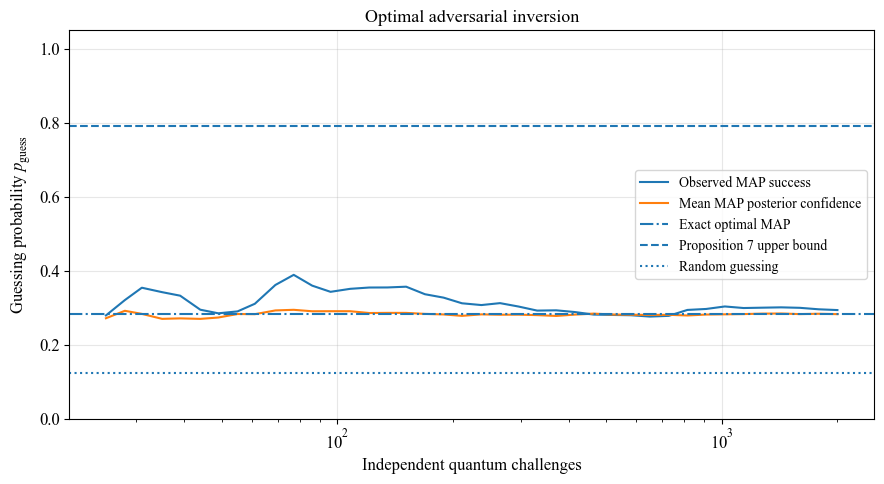

In [107]:
# ============================================================
# PROPOSITION 7 — OPTIMAL ATTACK CONVERGENCE
# ============================================================

checkpoints = np.unique(
    np.geomspace(
        ADV_MIN_CHECKPOINT,
        ADV_TRIALS,
        num=ADV_N_CHECKPOINTS,
    ).round().astype(int)
)

success = attack_df["Correct"].to_numpy(dtype=float)
confidence = attack_df["Confidence"].to_numpy(dtype=float)

empirical = np.cumsum(success)[checkpoints - 1] / checkpoints
posterior_estimate = (
    np.cumsum(confidence)[checkpoints - 1] / checkpoints
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    checkpoints, empirical,
    label="Observed MAP success",
)

ax.plot(
    checkpoints, posterior_estimate,
    label="Mean MAP posterior confidence",
)

if p_optimal is not None:
    ax.axhline(
        p_optimal,
        linestyle="-.",
        label="Exact optimal MAP",
    )

ax.axhline(
    min(1.0, raw_bound),
    linestyle="--",
    label="Proposition 7 upper bound",
)

ax.axhline(
    2**(-ADV_N),
    linestyle=":",
    label="Random guessing",
)

ax.set_xlabel("Independent quantum challenges")
ax.set_ylabel(r"Guessing probability $p_{\mathrm{guess}}$")
ax.set_title("Optimal adversarial inversion")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
ax.set_xscale("log")
plt.tight_layout()
save_pdf(fig, "proposition_7_optimal_inversion")
plt.show()


### Interpretation of the optimal inversion experiment

The experiment evaluates the optimal Bayesian adversary
against transcripts generated by the actual Qiskit circuits.

Every challenge uses a new uniformly random input and fresh,
independent secret matrices. The adversary observes all
$\nu$ measurement transcripts but does not know the keys.

The observed MAP success rate estimates the adversary's
actual inversion probability.

The exact optimal MAP probability provides a benchmark for
the strongest possible classical decision rule using these
transcripts and the specified prior.

The Proposition 7 bound provides a theoretical upper bound
and is not necessarily tight.

Increasing the number of independent challenges improves
the statistical estimate; it does not make the attacker
progressively stronger.

The empirical success rate and mean posterior confidence
are expected to approach the exact optimal MAP probability
as the number of challenges increases.



### Proposition 7 — Inversion security across model configurations

We investigate how the adversary's inversion probability
depends on the construction parameters $n$, $s$, and $\nu$.

For each parameter configuration, we execute independent
quantum inversion challenges using freshly generated uniform
inputs and secret keys.

Every challenge includes exactly $\nu$ independently keyed
Qiskit circuits, executed once each on the same input $X$.

The MAP adversary observes the resulting transcripts but
does not know the secret keys.

We compare:

- Empirical MAP inversion success.
- Exact optimal guessing probability, when feasible.
- The upper bound of Proposition 7.
- The random guessing baseline $2^{-n}$.

Increasing $\nu$ provides additional observations of the
same unknown input. Increasing $s$ changes the information
contained in each measured tag.

These variations affect both authorized correctness and
adversarial inversion security, but in different ways.

The number of challenges is kept fixed within each
configuration to allow a fair statistical comparison.


In [108]:
# ============================================================
# PROPOSITION 7 — PARAMETER SWEEP
# ============================================================

from qiskit_aer import AerSimulator

# CONFIGURATION — MODIFY HERE
SWEEP_N_VALUES = [3, 4, 5]
SWEEP_S_VALUES = list(range(1, 6))
SWEEP_NU_VALUES = list(range(1, 8))

SWEEP_TRIALS = 1200
SWEEP_BATCH_SIZE = 60
SWEEP_SEED = 4040

def evaluate_map_attack(n, s, nu, trials, seed):
    """Evaluate MAP success on actual Qiskit circuit transcripts."""
    rng = np.random.default_rng(seed)
    attack_rng = np.random.default_rng(seed + 1)
    simulator = AerSimulator(method="stabilizer")

    correct = 0

    for start in range(0, trials, SWEEP_BATCH_SIZE):
        batch = min(SWEEP_BATCH_SIZE, trials - start)
        circuits, challenges = [], []

        for _ in range(batch):
            x = int(rng.integers(0, 2**n))
            keys = rng.integers(
                0, 2, size=(nu, s, n), dtype=np.uint8
            )

            instance = KeyedLinearTagModel(
                n=n, s=s, nu=nu, key_matrices=keys
            )
            challenges.append((x, instance))

            for j in range(nu):
                circuits.append(
                    instance.circuit(x=x, block=j, measure=True)
                )

        result = simulator.run(
            circuits,
            shots=1,
            seed_simulator=int(rng.integers(1, 2**31)),
        ).result()

        for k, (x, instance) in enumerate(challenges):
            records = [
                instance.parse_outcome(
                    next(iter(result.get_counts(k * nu + j)))
                )
                for j in range(nu)
            ]

            guess, _ = map_attacker(records, n, s, attack_rng)
            correct += int(guess == x)

    return correct / trials


sweep_rows = []

for n in SWEEP_N_VALUES:
    for s in SWEEP_S_VALUES:
        for nu in SWEEP_NU_VALUES:

            if not (1 <= s <= n and 1 <= nu < 2**n):
                continue

            seed = SWEEP_SEED + 1000*n + 100*s + nu

            empirical = evaluate_map_attack(
                n, s, nu, SWEEP_TRIALS, seed
            )

            exact = exact_map_success(
                n, s, nu,
                max_outcomes=MAX_EXACT_OUTCOMES,
            )

            bound = (
                2**s / (2**n - nu)
                + nu*(nu - 1) / 2**(n + 1)
            )

            sweep_rows.append({
                "n": n,
                "s": s,
                "nu": nu,
                "Empirical MAP": empirical,
                "Exact MAP": exact,
                "Proposition 7 bound": min(1.0, bound),
                "Random baseline": 2**(-n),
            })

sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df)

,n,s,nu,Empirical MAP,Exact MAP,Proposition 7 bound,Random baseline
0,3,1,1,0.187500,0.187500,0.285714,0.12500
1,3,1,2,0.215000,0.218750,0.458333,0.12500
2,3,1,3,0.234167,0.244629,0.775000,0.12500
3,3,1,4,0.256667,0.269745,1.000000,0.12500
4,3,1,5,0.269167,NaN,1.000000,0.12500
...,...,...,...,...,...,...,...
79,5,5,3,0.109167,NaN,1.000000,0.03125
80,5,5,4,0.131667,NaN,1.000000,0.03125
81,5,5,5,0.161667,NaN,1.000000,0.03125
82,5,5,6,0.186667,NaN,1.000000,0.03125


Saved: /Users/jackvittori/Desktop/ISCAS2027/res/proposition_7_parameter_sweep_n3.pdf


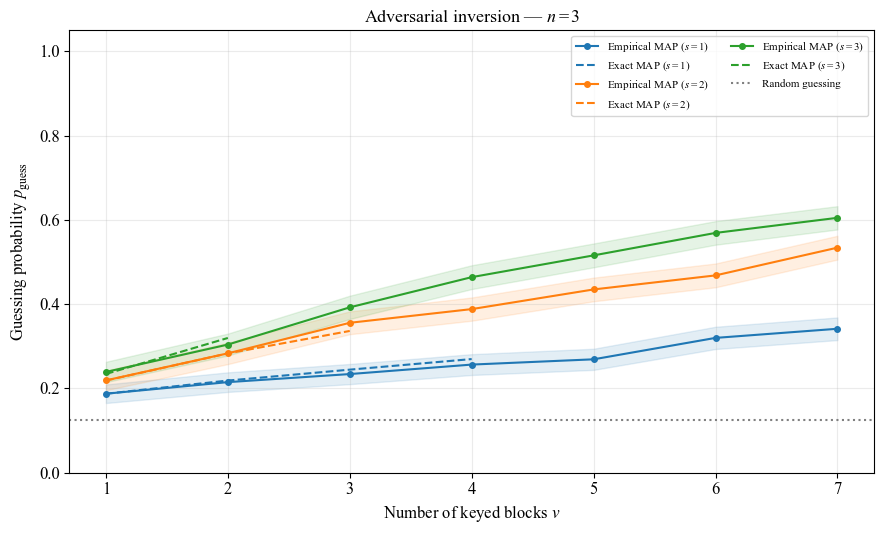

Saved: /Users/jackvittori/Desktop/ISCAS2027/res/proposition_7_parameter_sweep_n4.pdf


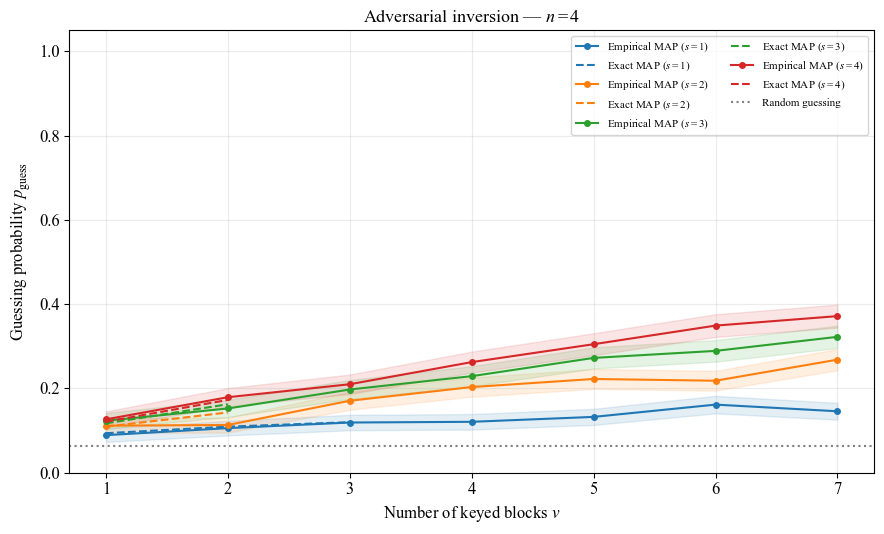

Saved: /Users/jackvittori/Desktop/ISCAS2027/res/proposition_7_parameter_sweep_n5.pdf


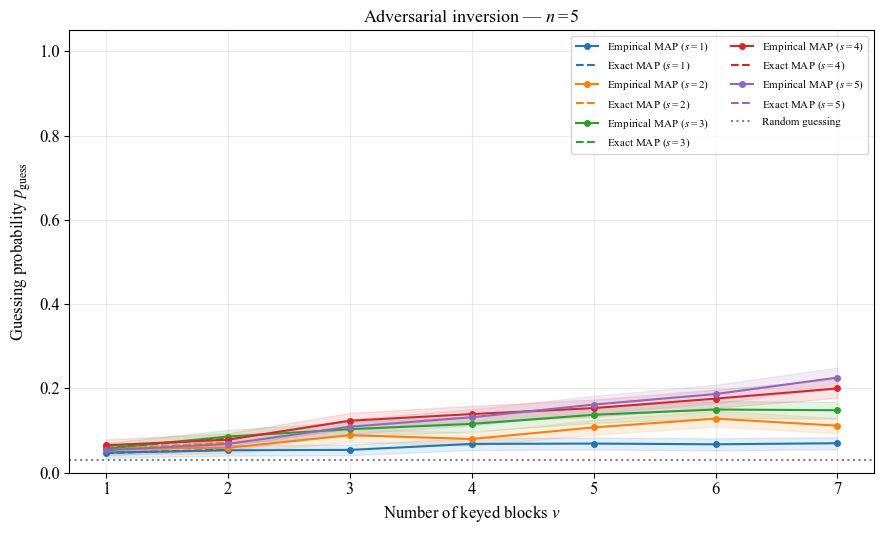

In [109]:
# ============================================================
# PROPOSITION 7 — EXTENDED PARAMETER SWEEP FIGURES
# ============================================================

for n in sorted(sweep_df["n"].unique()):

    data_n = sweep_df[sweep_df["n"] == n]
    fig, ax = plt.subplots(figsize=(9, 5.5))

    for s in sorted(data_n["s"].unique()):

        data = data_n[data_n["s"] == s].sort_values("nu")

        x = data["nu"].to_numpy(dtype=int)
        y = data["Empirical MAP"].to_numpy(dtype=float)

        # Approximate 95% binomial confidence interval.
        error = 1.96 * np.sqrt(y * (1 - y) / SWEEP_TRIALS)

        line, = ax.plot(
            x, y, marker="o", markersize=4,
            label=rf"Empirical MAP ($s={s}$)",
        )

        ax.fill_between(
            x,
            np.maximum(0, y - error),
            np.minimum(1, y + error),
            color=line.get_color(),
            alpha=0.12,
        )

        exact_data = data.dropna(subset=["Exact MAP"])

        if not exact_data.empty:
            ax.plot(
                exact_data["nu"],
                exact_data["Exact MAP"],
                linestyle="--",
                color=line.get_color(),
                label=rf"Exact MAP ($s={s}$)",
            )

    ax.axhline(
        2.0**(-int(n)),
        color="gray",
        linestyle=":",
        label="Random guessing",
    )

    ax.set_xticks(sorted(data_n["nu"].unique()))
    ax.set_xlabel(r"Number of keyed blocks $\nu$")
    ax.set_ylabel(r"Guessing probability $p_{\mathrm{guess}}$")
    ax.set_title(rf"Adversarial inversion — $n={n}$")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, ncol=2)

    plt.tight_layout()
    save_pdf(fig, f"proposition_7_parameter_sweep_n{n}")
    plt.show()


### Interpretation of the parameter sweep

The experiment evaluates how inversion security changes
with the number of independently keyed blocks and the
tag width.

Unlike the previous convergence experiment, the horizontal
axis represents the number of observations available to
the adversary within each challenge.

Increasing $\nu$ gives the adversary more information about
the same hidden input. Increasing $s$ modifies the
key-averaged information carried by each tag.

The exact MAP curves quantify optimal inversion performance,
while the empirical curves estimate that performance using
measurement transcripts generated by the Qiskit circuits.

The Proposition 7 bound is also reported in the numerical
table. It can be conservative or even exceed one, in which
case it provides no nontrivial probability guarantee.

The experiment illustrates the tradeoff between authorized
decoding reliability and adversarial inversion security.
